# 13 — External references: how do other CPUs and GPUs do on the same model?

**Objective.** Place our measurements (Xeon CPU Max 9480, one socket, HBM cache mode) next to published results for the same
model, Llama-3.1-8B, so that later work starts from a calibrated view: where we are far off, where we are close, and which
metric (throughput, time to first token, time per output token, energy) separates the systems most.

**Research questions.**
1. How do our BF16 and INT8 throughputs compare with other CPUs (Xeon 6, Arm) and with GPUs (L40S, H100, H200, B200)?
2. Where is the gap smallest: throughput, TTFT, TPOT or energy per token?
3. How much of each system's memory bandwidth does single-stream decode use (ours against the GPUs')?

**Data.**
- `data/external/reference_results.csv`: one row per published measurement, built by
  `scripts/processing/build_external_references.py` from the sources in `data/external/sources.csv`. Machine-readable
  sources (ML.ENERGY leaderboard, NVIDIA NIM tables, MLPerf v5.1 summaries) are parsed. The rest (Lenovo LP2463, Arm, Red
  Hat) are transcribed in `manual_results.csv`, and Lenovo's values are digitised from its figures.
- Our points come from the primary online campaign (`online_points.csv`, 8B).
- The model is **Llama-3.1-8B-Instruct**. Llama-3.2-1B is our cross-check model, but no BF16 serving results for it were
  found online, and we do not use Llama-3.2-3B.

**How to read the ratios.** Every external row is paired with our nearest point. The pairing uses the same precision
class, the nearest workload shape (log distance of ISL and OSL) and the nearest concurrency of that sweep. For MLPerf, which
reports throughput only, it uses our peak over the sweep. All ratios are *external advantage* factors: > 1 means the
external system is better. For throughput that is external ÷ ours; for TTFT, TPOT and energy it is ours ÷ external. The
vLLM configuration of each precision class (the selected backend) is the reference, and llama.cpp is reported alongside.
Grades: **A** = same model, precision, shape and C; **B** = same model and precision class, other shape; **C** = loosely
comparable.

**Our energy is an estimate, not a measurement.** RAPL is not readable on CRESCO8 (see `docs/methodology.md`). Our J/token is
`POWER_W` ÷ output tok/s, with `POWER_W` = 350 W, the TDP of the one socket the server uses. It is a placeholder that leaves
out DRAM, the second socket and the platform. Setting `POWER_W` to a measured value (e.g. Slurm `ConsumedEnergy` ÷ duration)
regenerates every energy column below.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import external
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "13_external_references.ipynb"
POWER_W = external.POWER_W_ASSUMED   # replace by a measured average power of the server socket when one exists
keys = pd.read_csv(paths.TABLES / "backend_selection" / "key_numbers.csv").set_index("key")
STREAM_GBS = float(keys.loc["roof_memory_in_hbm_cache_gbs", "low"])

refs = external.references()
points = loaders.online_points(model=registry.primary_model())
comp = external.compare(refs, points, power_w=POWER_W)
src = external.sources()
KEYS = []


def key(name, values, fmt, description):
    v = pd.Series(values, dtype=float).dropna()
    KEYS.append({"key": name, "text": rng(v, fmt) if len(v) else "–", "low": v.min(), "high": v.max(), "n": len(v),
                 "description": description})


def ratio(v):
    return x(v, 2) if v < 10 else x(v, 1)

## 1. Sources and how comparable they are

In [2]:
cnt = comp.groupby(["source_id", "grade"]).size().unstack(fill_value=0).reindex(columns=["A", "B", "C"], fill_value=0)
s = src.set_index("source_id")[["title", "publisher", "kind", "accessed"]].join(cnt).reset_index()
display(table(s.rename(columns={"source_id": "Source", "title": "Document", "publisher": "Publisher", "kind": "Kind", "accessed": "Accessed",
                                "A": "Grade A rows", "B": "Grade B rows", "C": "Grade C rows"}), align="left"))
g = comp["grade"].value_counts()
show(f"{len(refs)} published measurements from {refs['source_id'].nunique()} sources: {int(g.get('A', 0))} of grade A, {int(g.get('B', 0))} of grade B, "
     f"{int(g.get('C', 0))} of grade C. No source runs one of our exact shapes (128→512, 512→512, 4096→128, 8192→256, 4096→1024), so nothing reaches grade A. "
     f"The closest are the fixed-shape closed-loop sweeps: NVIDIA NIM at 1000→1000 and others, and Lenovo's Xeon 6 vLLM runs at 256→256.")

Source,Document,Publisher,Kind,Accessed,Grade A rows,Grade B rows,Grade C rows
mlenergy_v3,"The ML.ENERGY Leaderboard v3.0, task LM Arena chat (leaderboard data file)",ML.ENERGY Initiative (University of Michigan),independent,2026-10-18,0,0,20
nvidia_nim,"NVIDIA NIM LLM Benchmarking 1.0.0, Performance (Llama-3.1-8b-instruct results)",NVIDIA,vendor,2026-10-18,0,176,39
mlperf_v51_intel,"MLPerf Inference v5.1 Datacenter (closed), Intel 1-node-2S-GNR_128C, llama3_1-8b",MLCommons / Intel,audited,2026-10-18,0,0,2
mlperf_v51_lenovo,"MLPerf Inference v5.1 Datacenter (closed), Lenovo ThinkSystem SR650 V4 GNR 86C, llama3_1-8b",MLCommons / Lenovo,audited,2026-10-18,0,0,2
redhat_mlperf_v51,Efficient and reproducible LLM inference: Red Hat MLPerf Inference v5.1 results,Red Hat,vendor,2026-10-18,0,0,4
lenovo_lp2463,"Power-Efficient LLM Inference with Intel Xeon 6 Processors (LP2463, E. Page, 2 July 2026)",Lenovo Press,vendor,2026-10-18,0,21,0
arm_vllm_quant,Arm Learning Path: Benchmark Llama throughput (vLLM BF16 vs INT8 W8A8),Arm,vendor,2026-10-18,0,0,2


266 published measurements from 7 sources: 0 of grade A, 197 of grade B, 69 of grade C. No source runs one of our exact shapes (128→512, 512→512, 4096→128, 8192→256, 4096→1024), so nothing reaches grade A. The closest are the fixed-shape closed-loop sweeps: NVIDIA NIM at 1000→1000 and others, and Lenovo's Xeon 6 vLLM runs at 256→256.

**Kinds of source.** *Audited* means MLPerf, reviewed by the other submitters. *Independent* means the academic ML.ENERGY
benchmark. *Vendor* means the documentation or white papers of NVIDIA, Lenovo, Arm and Red Hat. Vendor numbers are
best-case configurations of their own products.

## 2. Other CPUs

### 2.1 BF16: Xeon 6 with vLLM (Lenovo LP2463) and Arm with vLLM

Lenovo runs the same engine family as us (vLLM CPU 0.21, BF16) on three Xeon 6 SKUs at 256→256, from 1 to 128 users. Our
nearest shape is 128→512. The paper does not say whether one or both sockets of its dual-socket servers served the model,
so the comparison is per system, not per socket. Its values are digitised from Figures 1–2. Aggregate tok/s is per-user
tok/s × users.

In [3]:
cpu_bf16 = comp[(comp["hardware_class"] == "cpu") & (comp["precision_group"] == "bf16")]
cols = {"hardware": "System", "workload": "Shape", "concurrency": "C", "output_tok_s": "External tok/s", "ttft_s": "External TTFT (s)",
        "our_workload": "Our shape", "our_concurrency": "Our C", "ours_output_tok_s": "vLLM BF16 tok/s", "ours_ttft_s": "vLLM BF16 TTFT (s)",
        "other_output_tok_s": "llama.cpp BF16 tok/s", "adv_throughput": "Throughput ext ÷ ours", "adv_ttft": "TTFT ours ÷ ext", "grade": "Grade"}
display(table(cpu_bf16.assign(our_workload=cpu_bf16["our_workload"].map(lambda w: registry.workload_label(w, short=True)))[list(cols)].rename(columns=cols),
              {"C": "{:.0f}", "External tok/s": "{:.1f}", "External TTFT (s)": "{:.2f}", "Our C": "{:.0f}", "vLLM BF16 tok/s": "{:.1f}",
               "vLLM BF16 TTFT (s)": "{:.2f}", "llama.cpp BF16 tok/s": "{:.1f}", "Throughput ext ÷ ours": "{:.2f}×", "TTFT ours ÷ ext": "{:.2f}×"}, align="left"))
le = cpu_bf16[cpu_bf16["source_id"] == "lenovo_lp2463"]
by = {h: g for h, g in le.groupby("hardware")}
c1 = le[le["concurrency"] == 1].set_index("hardware")
arm = cpu_bf16[cpu_bf16["source_id"] == "arm_vllm_quant"].iloc[0]
show(f"**Throughput.** Against vLLM BF16 at the same C, the 96-core Xeon 6972P delivers {rng(by['Intel Xeon 6972P']['adv_throughput'], ratio)} our output tok/s "
     f"and the 72-core 6960P {rng(by['Intel Xeon 6960P']['adv_throughput'], ratio)}. The 32-core 6732P delivers {rng(by['Intel Xeon 6732P']['adv_throughput'], ratio)}, "
     f"so our 55-core Xeon Max socket sits between the 32-core and the 72/96-core Xeon 6 parts. "
     f"Single stream (C = 1): {num(c1.loc['Intel Xeon 6972P', 'output_tok_s'], 1)} and {num(c1.loc['Intel Xeon 6960P', 'output_tok_s'], 1)} tok/s for the 96- and 72-core SKUs "
     f"against our {num(c1['ours_output_tok_s'].iloc[0], 1)} (vLLM BF16, 128→512) and {num(c1['other_output_tok_s'].iloc[0], 1)} (llama.cpp BF16).")
le8 = le[le["concurrency"] >= 8]
show(f"**TTFT.** From C = 8 upward our median TTFT is {rng(le8['adv_ttft'], ratio)} Lenovo's (ours ÷ external), so ours is lower. At C = 4 it is "
     f"{rng(le[le['concurrency'] == 4]['adv_ttft'], ratio)} (ours higher where both are a few hundred milliseconds or less). Part of the difference is the shape, "
     f"because our prompts are 128 tokens and theirs 256, and part is queueing in their run. "
     f"Arm (96 Neoverse cores, vLLM BF16, ShareGPT at request rate 8, max concurrency {int(arm['concurrency'])}) reaches {num(arm['output_tok_s'], 1)} output tok/s, "
     f"{ratio(arm['adv_throughput'])} of our vLLM BF16 at C = {int(arm['our_concurrency'])} on 128→512 (grade C: other dataset and arrival process).")
key("ext_cpu_bf16_xeon6_96c_over_ours", by["Intel Xeon 6972P"]["adv_throughput"], ratio, "Xeon 6972P (96 cores, vLLM BF16, 256→256) output tok/s ÷ ours (vLLM BF16, 128→512), same C = 1…128 (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_72c_over_ours", by["Intel Xeon 6960P"]["adv_throughput"], ratio, "Xeon 6960P (72 cores) output tok/s ÷ ours, same C (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_32c_over_ours", by["Intel Xeon 6732P"]["adv_throughput"], ratio, "Xeon 6732P (32 cores) output tok/s ÷ ours, same C (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_ttft_ours_over_ext", le8["adv_ttft"], ratio, "Our TTFT ÷ Lenovo's Xeon 6 TTFT, same C = 8…128 (< 1: ours lower; our prompts are shorter)")

System,Shape,C,External tok/s,External TTFT (s),Our shape,Our C,vLLM BF16 tok/s,vLLM BF16 TTFT (s),llama.cpp BF16 tok/s,Throughput ext ÷ ours,TTFT ours ÷ ext,Grade
"Arm Neoverse server, 96 cores (128-bit SVE, 192 GB)",ShareGPT (256 prompts),10,64.3,0.61,128→512,8,137.2,0.18,86.6,0.47×,0.30×,C
Intel Xeon 6732P,256→256,1,15.2,–,128→512,1,18.5,0.14,21.6,0.82×,–,B
Intel Xeon 6732P,256→256,4,54.5,–,128→512,4,71.4,0.18,62.8,0.76×,–,B
Intel Xeon 6732P,256→256,8,100.5,0.74,128→512,8,137.2,0.18,86.6,0.73×,0.25×,B
Intel Xeon 6732P,256→256,16,187.4,1.39,128→512,16,254.8,0.19,110.0,0.74×,0.14×,B
Intel Xeon 6732P,256→256,32,320.3,2.37,128→512,32,420.0,0.21,124.5,0.76×,0.09×,B
Intel Xeon 6732P,256→256,64,423.7,3.46,128→512,64,628.2,0.26,125.4,0.67×,0.07×,B
Intel Xeon 6732P,256→256,128,531.2,4.81,128→512,128,700.4,0.39,125.4,0.76×,0.08×,B
Intel Xeon 6960P,256→256,1,28.8,–,128→512,1,18.5,0.14,21.6,1.56×,–,B
Intel Xeon 6960P,256→256,4,100.2,–,128→512,4,71.4,0.18,62.8,1.40×,–,B


**Throughput.** Against vLLM BF16 at the same C, the 96-core Xeon 6972P delivers 1.45×–1.60× our output tok/s and the 72-core 6960P 1.21×–1.56×. The 32-core 6732P delivers 0.67×–0.82×, so our 55-core Xeon Max socket sits between the 32-core and the 72/96-core Xeon 6 parts. Single stream (C = 1): 28.4 and 28.8 tok/s for the 96- and 72-core SKUs against our 18.5 (vLLM BF16, 128→512) and 21.6 (llama.cpp BF16).

**TTFT.** From C = 8 upward our median TTFT is 0.07×–0.62× Lenovo's (ours ÷ external), so ours is lower. At C = 4 it is 1.91× (ours higher where both are a few hundred milliseconds or less). Part of the difference is the shape, because our prompts are 128 tokens and theirs 256, and part is queueing in their run. Arm (96 Neoverse cores, vLLM BF16, ShareGPT at request rate 8, max concurrency 10) reaches 64.3 output tok/s, 0.47× of our vLLM BF16 at C = 8 on 128→512 (grade C: other dataset and arrival process).

### 2.2 8-bit: Arm (W8A8) and the CPU-only MLPerf v5.1 submissions

The MLPerf rows are dual-socket Granite Rapids servers on CNN-DailyMail summarisation: 778 input and 73 output tokens on
average, Offline and Server scenarios. Intel's submission declares INT4 weights with INT8 activations; Lenovo's declares
INT8/INT8. The shape has no counterpart among ours, so they are compared on *total* (prompt + output) tokens/s per socket
against our peak total tokens/s on the nearest shape (4096→128, vLLM W8A8). This is context, not a ratio to rely on.

In [4]:
cpu8 = comp[(comp["hardware_class"] == "cpu") & (comp["precision_group"] != "bf16")]
cols = {"source_id": "Source", "hardware": "System", "precision": "Precision", "scenario": "Scenario", "devices": "Sockets", "output_tok_s": "External output tok/s",
        "ext_total_tok_s": "External total tok/s", "our_workload": "Our shape", "our_basis": "Our point", "ours_output_tok_s": "vLLM W8A8 output tok/s",
        "ours_total_tok_s": "vLLM W8A8 total tok/s", "adv_throughput": "Output ext ÷ ours", "adv_total_throughput_per_device": "Total per socket ext ÷ ours", "grade": "Grade"}
display(table(cpu8.assign(our_workload=cpu8["our_workload"].map(lambda w: registry.workload_label(w, short=True)))[list(cols)].rename(columns=cols),
              {"Sockets": "{:.0f}", "External output tok/s": "{:.1f}", "External total tok/s": "{:.0f}", "vLLM W8A8 output tok/s": "{:.1f}",
               "vLLM W8A8 total tok/s": "{:.0f}", "Output ext ÷ ours": "{:.2f}×", "Total per socket ext ÷ ours": "{:.2f}×"}, align="left"))
mp = cpu8[cpu8["source_id"].str.startswith("mlperf")]
arm8 = cpu8[cpu8["source_id"] == "arm_vllm_quant"].iloc[0]
show(f"Per socket, the MLPerf CPU systems process {rng(mp[mp['scenario'] == 'mlperf_offline']['adv_total_throughput_per_device'], ratio)} our peak total tokens/s in Offline "
     f"(unconstrained batching) and {rng(mp[mp['scenario'] == 'mlperf_server']['adv_total_throughput_per_device'], ratio)} in Server (TTFT and TPOT limits). "
     f"Arm with W8A8 reaches {num(arm8['output_tok_s'], 1)} output tok/s at max concurrency {int(arm8['concurrency'])}, "
     f"{ratio(arm8['adv_throughput'])} of our vLLM W8A8 at C = {int(arm8['our_concurrency'])}.")
key("ext_mlperf_cpu_offline_total_per_socket_over_ours", mp[mp["scenario"] == "mlperf_offline"]["adv_total_throughput_per_device"], ratio,
    "MLPerf v5.1 CPU-only (2× Xeon 6980P W4A8; 2× Xeon 6787P W8A8) Offline total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128")
key("ext_mlperf_cpu_server_total_per_socket_over_ours", mp[mp["scenario"] == "mlperf_server"]["adv_total_throughput_per_device"], ratio,
    "MLPerf v5.1 CPU-only Server total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128")

Source,System,Precision,Scenario,Sockets,External output tok/s,External total tok/s,Our shape,Our point,vLLM W8A8 output tok/s,vLLM W8A8 total tok/s,Output ext ÷ ours,Total per socket ext ÷ ours,Grade
arm_vllm_quant,"Arm Neoverse server, 96 cores (128-bit SVE, 192 GB)",w8a8,request_rate,1,138.4,396,128→512,nearest C,721.2,895,0.19×,0.44×,C
mlperf_v51_intel,Intel Xeon 6980P,w4a8,mlperf_offline,2,1232.9,14372,4096→128,peak over C,103.6,2553,11.90×,2.81×,C
mlperf_v51_intel,Intel Xeon 6980P,w4a8,mlperf_server,2,450.8,5256,4096→128,peak over C,103.6,2553,4.35×,1.03×,C
mlperf_v51_lenovo,Intel Xeon 6787P,w8a8,mlperf_offline,2,776.9,9056,4096→128,peak over C,103.6,2553,7.50×,1.77×,C
mlperf_v51_lenovo,Intel Xeon 6787P,w8a8,mlperf_server,2,275.8,3215,4096→128,peak over C,103.6,2553,2.66×,0.63×,C


Per socket, the MLPerf CPU systems process 1.77×–2.81× our peak total tokens/s in Offline (unconstrained batching) and 0.63×–1.03× in Server (TTFT and TPOT limits). Arm with W8A8 reaches 138.4 output tok/s at max concurrency 24, 0.19× of our vLLM W8A8 at C = 32.

## 3. GPUs

### 3.1 BF16: NVIDIA NIM (L40S, H100, H200) and ML.ENERGY (H100, B200)

NIM gives closed-loop sweeps at fixed shapes. Only 1000→1000 is published in BF16; our nearest shape is 512→512. Their
TTFT and ITL are means, ours are medians of per-repetition medians. ML.ENERGY runs vLLM 0.11.1 on LM Arena chat prompts with
the maximum batch size swept. Its prompt lengths are not published, so its rows are matched on output length only (grade C).

In [5]:
gpu = comp[comp["hardware_class"] == "gpu"]
nim_bf16 = gpu[(gpu["source_id"] == "nvidia_nim") & (gpu["precision"] == "bf16")]
summ = (nim_bf16.groupby("hardware", sort=False)
        .apply(lambda g: pd.Series({"C": f"{int(g['concurrency'].min())}–{int(g['concurrency'].max())}",
                                    "tok/s ext ÷ ours": rng(g["adv_throughput"], ratio),
                                    "TPOT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_tpot"].iloc[0]),
                                    "TTFT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_ttft"].iloc[0]),
                                    "TTFT ours ÷ ext, C≥50": rng(g.loc[g["concurrency"] >= 50, "adv_ttft"], ratio),
                                    "peak ext tok/s": num(g["output_tok_s"].max()), "our peak tok/s": num(g["ours_output_tok_s"].max())}), include_groups=False)
        .reset_index().rename(columns={"hardware": "GPU (NIM, BF16, 1000→1000) vs vLLM BF16 512→512"}))
display(table(summ, align="left"))
h = {k: g for k, g in nim_bf16.groupby("hardware")}
BW = external.hardware_specs().set_index("hardware")["peak_mem_bw_gbs"]
show(f"**Throughput.** One H100 delivers {rng(h['NVIDIA H100 SXM 80GB']['adv_throughput'], ratio)} our vLLM BF16 output tok/s over the sweep, an H200 "
     f"{rng(h['NVIDIA H200 SXM 141GB']['adv_throughput'], ratio)}, an L40S {rng(h['NVIDIA L40S 48GB (PCIe)']['adv_throughput'], ratio)}. "
     f"The gap widens at high C because the GPUs keep scaling past our C = 128 plateau (above 128 the ratio is to our highest C). "
     f"**Single-stream decode** (TPOT at C = 1) is {ratio(h['NVIDIA H100 SXM 80GB'].query('concurrency == 1')['adv_tpot'].iloc[0])} faster on the H100 and "
     f"{ratio(h['NVIDIA L40S 48GB (PCIe)'].query('concurrency == 1')['adv_tpot'].iloc[0])} on the L40S. Their peak memory bandwidths are "
     f"{ratio(BW['NVIDIA H100 SXM 80GB'] / STREAM_GBS)} and {ratio(BW['NVIDIA L40S 48GB (PCIe)'] / STREAM_GBS)} our measured roof, so most of the decode gap is bandwidth (section 5).")
hi = nim_bf16[nim_bf16["concurrency"].between(50, 200) & nim_bf16["hardware"].isin(["NVIDIA H100 SXM 80GB", "NVIDIA H200 SXM 141GB"])]
sat = nim_bf16[nim_bf16["adv_ttft"] < 0.5]
sat_txt = ", ".join(f"{hw.removeprefix('NVIDIA ')} at C ≥ {int(c)}" for hw, c in sat.groupby("hardware")["concurrency"].min().items())
show(f"**TTFT is where we are closest.** On the H100 and H200 at C = 50–200 our median TTFT is {rng(hi['adv_ttft'], ratio)} their mean TTFT, so they are comparable. "
     f"Our 512-token prompts are half theirs, which favours us. Where a GPU saturates "
     f"({sat_txt}), "
     f"its queueing makes TTFT longer than ours (ours ÷ external down to {ratio(sat['adv_ttft'].min())}). "
     f"At C = 1 the GPUs prefill {rng(nim_bf16[nim_bf16['concurrency'] == 1]['adv_ttft'], ratio)} faster.")
key("ext_gpu_bf16_h100_over_ours", h["NVIDIA H100 SXM 80GB"]["adv_throughput"], ratio, "NIM H100 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C (C = 1…250)")
key("ext_gpu_bf16_h200_over_ours", h["NVIDIA H200 SXM 141GB"]["adv_throughput"], ratio, "NIM H200 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C")
key("ext_gpu_bf16_l40s_over_ours", h["NVIDIA L40S 48GB (PCIe)"]["adv_throughput"], ratio, "NIM L40S BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C")
key("ext_gpu_bf16_tpot_c1_over_ours", nim_bf16[nim_bf16["concurrency"] == 1]["adv_tpot"], ratio, "Our C=1 median TPOT ÷ NIM mean ITL (L40S, H100, H200; BF16)")
key("ext_gpu_bf16_ttft_high_c", hi["adv_ttft"], ratio, "Our median TTFT ÷ NIM mean TTFT, H100 and H200 BF16 at C = 50…200 (< 1: ours lower; our prompts are shorter)")

"GPU (NIM, BF16, 1000→1000) vs vLLM BF16 512→512",C,tok/s ext ÷ ours,"TPOT ours ÷ ext, C=1","TTFT ours ÷ ext, C=1","TTFT ours ÷ ext, C≥50",peak ext tok/s,our peak tok/s
NVIDIA H100 SXM 80GB,1–250,7.67×–15.1×,8.10×,15.3×,0.21×–1.21×,"7,435",491
NVIDIA H200 SXM 141GB,1–250,7.50×–17.9×,7.43×,14.6×,0.56×–1.04×,"8,813",491
NVIDIA L40S 48GB (PCIe),1–200,2.37×–3.30×,2.40×,5.20×,0.02×–1.86×,"1,619",491


**Throughput.** One H100 delivers 7.67×–15.1× our vLLM BF16 output tok/s over the sweep, an H200 7.50×–17.9×, an L40S 2.37×–3.30×. The gap widens at high C because the GPUs keep scaling past our C = 128 plateau (above 128 the ratio is to our highest C). **Single-stream decode** (TPOT at C = 1) is 8.10× faster on the H100 and 2.40× on the L40S. Their peak memory bandwidths are 6.67× and 1.72× our measured roof, so most of the decode gap is bandwidth (section 5).

**TTFT is where we are closest.** On the H100 and H200 at C = 50–200 our median TTFT is 0.79×–1.21× their mean TTFT, so they are comparable. Our 512-token prompts are half theirs, which favours us. Where a GPU saturates (H100 SXM 80GB at C ≥ 250, L40S 48GB (PCIe) at C ≥ 100), its queueing makes TTFT longer than ours (ours ÷ external down to 0.02×). At C = 1 the GPUs prefill 5.20×–15.3× faster.

In [6]:
me = gpu[gpu["source_id"] == "mlenergy_v3"]
cols = {"hardware": "GPU", "concurrency": "Max batch", "output_tok_s": "Output tok/s", "tpot_s": "Median ITL (s)", "our_concurrency": "Our C",
        "our_basis": "Our point", "ours_output_tok_s": "vLLM BF16 tok/s (128→512)", "ours_tpot_s": "vLLM BF16 TPOT (s)",
        "adv_throughput": "Throughput ext ÷ ours", "adv_tpot": "TPOT ours ÷ ext"}
display(table(me[list(cols)].rename(columns=cols), {"Max batch": "{:.0f}", "Output tok/s": "{:,.0f}", "Median ITL (s)": "{:.4f}", "Our C": "{:.0f}",
                                                   "vLLM BF16 tok/s (128→512)": "{:.0f}", "vLLM BF16 TPOT (s)": "{:.3f}", "Throughput ext ÷ ours": "{:.1f}×",
                                                   "TPOT ours ÷ ext": "{:.1f}×"}, align="left"))
same = me[me["our_basis"] == "same C"]
show(f"At equal batch (8–128) ML.ENERGY's H100 and B200 deliver {rng(same['adv_throughput'], ratio)} our vLLM BF16 output tok/s with "
     f"{rng(same['adv_tpot'], ratio)} shorter time per token. Their larger batches (up to {int(me['concurrency'].max())}) have no counterpart on our socket, which stops scaling near C = 128.")
key("ext_gpu_bf16_mlenergy_same_batch_over_ours", same["adv_throughput"], ratio, "ML.ENERGY v3 (H100, B200; vLLM 0.11.1 BF16, LM Arena chat) output tok/s ÷ ours (vLLM BF16 128→512) at equal batch 8–128")

GPU,Max batch,Output tok/s,Median ITL (s),Our C,Our point,vLLM BF16 tok/s (128→512),vLLM BF16 TPOT (s),Throughput ext ÷ ours,TPOT ours ÷ ext
NVIDIA B200 180GB,8,"1,637",0.0046,8,same C,137,0.058,11.9×,12.7×
NVIDIA B200 180GB,16,"2,751",0.0051,16,same C,255,0.063,10.8×,12.3×
NVIDIA B200 180GB,32,"3,810",0.0063,32,same C,420,0.076,9.1×,12.0×
NVIDIA B200 180GB,64,"5,589",0.0090,64,same C,628,0.102,8.9×,11.4×
NVIDIA B200 180GB,128,"4,570",0.0267,128,same C,700,0.184,6.5×,6.9×
NVIDIA B200 180GB,256,"7,664",0.0317,128,our highest C,700,0.184,10.9×,5.8×
NVIDIA B200 180GB,512,"9,571",0.0502,128,our highest C,700,0.184,13.7×,3.7×
NVIDIA B200 180GB,1024,"10,922",0.0871,128,our highest C,700,0.184,15.6×,2.1×
NVIDIA B200 180GB,2048,"14,799",0.1249,128,our highest C,700,0.184,21.1×,1.5×
NVIDIA H100 SXM 80GB,8,"1,070",0.0073,8,same C,137,0.058,7.8×,7.9×


At equal batch (8–128) ML.ENERGY's H100 and B200 deliver 6.53×–11.9× our vLLM BF16 output tok/s with 6.91×–12.7× shorter time per token. Their larger batches (up to 2048) have no counterpart on our socket, which stops scaling near C = 128.

### 3.2 8-bit: NIM FP8 against our vLLM W8A8, and Red Hat's MLPerf FP8 runs

FP8 (E4M3, per-tensor scales) is the GPU counterpart of our INT8 W8A8: the same bytes per weight, but a different number
format. That makes the rows grade B at best.

In [7]:
fp8 = gpu[(gpu["precision"] == "fp8") & (gpu["source_id"] == "nvidia_nim") & (gpu["engine_version"] == "1.8.0")]
summ8 = (fp8.groupby(["hardware", "workload"], sort=False)
         .apply(lambda g: pd.Series({"our shape": registry.workload_label(g["our_workload"].iloc[0], short=True),
                                     "tok/s ext ÷ ours": rng(g["adv_throughput"], ratio),
                                     "TPOT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_tpot"].iloc[0]),
                                     "TTFT ours ÷ ext": rng(g["adv_ttft"], ratio)}), include_groups=False).reset_index()
         .rename(columns={"hardware": "GPU (NIM 1.8.0, FP8)", "workload": "Shape"}))
display(table(summ8, align="left"))
rh = gpu[gpu["source_id"] == "redhat_mlperf_v51"]
display(table(rh[["hardware", "scenario", "output_tok_s", "ext_total_tok_s", "ours_total_tok_s", "adv_total_throughput_per_device"]]
              .rename(columns={"hardware": "GPU (Red Hat, vLLM 0.10.0, FP8)", "scenario": "MLPerf scenario", "output_tok_s": "Output tok/s",
                               "ext_total_tok_s": "Total tok/s", "ours_total_tok_s": "Our vLLM W8A8 peak total tok/s (4096→128)",
                               "adv_total_throughput_per_device": "Total ext ÷ ours"}),
              {"Output tok/s": "{:,.0f}", "Total tok/s": "{:,.0f}", "Our vLLM W8A8 peak total tok/s (4096→128)": "{:,.0f}", "Total ext ÷ ours": "{:.1f}×"}, align="left"))
f = {k: g for k, g in fp8.groupby("hardware")}
show(f"With 8-bit weights the GPU lead is {rng(f['NVIDIA H100 SXM 80GB']['adv_throughput'], ratio)} (H100), {rng(f['NVIDIA H200 SXM 141GB']['adv_throughput'], ratio)} (H200) and "
     f"{rng(f['NVIDIA L40S 48GB (PCIe)']['adv_throughput'], ratio)} (L40S) over all NIM shapes and concurrencies, of the same order as in BF16. "
     f"On MLPerf, one H100 processes {rng(rh[rh['hardware'].str.contains('H100')]['adv_total_throughput_per_device'], ratio)} and one L40S "
     f"{rng(rh[rh['hardware'].str.contains('L40S')]['adv_total_throughput_per_device'], ratio)} our peak total tokens/s.")
key("ext_gpu_8bit_h100_over_ours", f["NVIDIA H100 SXM 80GB"]["adv_throughput"], ratio, "NIM 1.8.0 H100 FP8 output tok/s ÷ our vLLM W8A8 (nearest shape and C)")
key("ext_gpu_8bit_l40s_over_ours", f["NVIDIA L40S 48GB (PCIe)"]["adv_throughput"], ratio, "NIM 1.8.0 L40S FP8 output tok/s ÷ our vLLM W8A8 (nearest shape and C)")
key("ext_mlperf_gpu_total_over_ours", rh["adv_total_throughput_per_device"], ratio, "Red Hat MLPerf v5.1 (H100, L40S; FP8 vLLM) total tok/s ÷ our vLLM W8A8 peak total tok/s, 4096→128")

"GPU (NIM 1.8.0, FP8)",Shape,our shape,tok/s ext ÷ ours,"TPOT ours ÷ ext, C=1",TTFT ours ÷ ext
NVIDIA H100 SXM 80GB,1000→1000,512→512,5.79×–15.0×,5.72×,0.23×–11.1×
NVIDIA H100 SXM 80GB,20000→2000,4096→1024,4.88×–7.07×,6.21×,0.01×–3.24×
NVIDIA H100 SXM 80GB,200→200,128→512,5.64×–12.8×,5.64×,0.65×–10.6×
NVIDIA H100 SXM 80GB,5000→500,4096→1024,6.86×–12.6×,6.81×,0.13×–16.8×
NVIDIA H100 SXM 80GB,500→2000,512→512,5.76×–16.3×,5.68×,0.07×–15.2×
NVIDIA H200 SXM 141GB,1000→1000,512→512,6.18×–16.7×,6.11×,0.19×–10.7×
NVIDIA H200 SXM 141GB,20000→2000,4096→1024,5.82×–8.12×,6.76×,0.01×–3.19×
NVIDIA H200 SXM 141GB,200→200,128→512,6.01×–13.1×,6.01×,0.72×–10.9×
NVIDIA H200 SXM 141GB,5000→500,4096→1024,7.24×–14.4×,7.21×,1.94×–16.3×
NVIDIA H200 SXM 141GB,500→2000,512→512,6.18×–17.6×,6.10×,0.05×–16.4×


"GPU (Red Hat, vLLM 0.10.0, FP8)",MLPerf scenario,Output tok/s,Total tok/s,Our vLLM W8A8 peak total tok/s (4096→128),Total ext ÷ ours
NVIDIA H100 SXM 80GB,mlperf_offline,"5,777","67,347","2,553",26.4×
NVIDIA H100 SXM 80GB,mlperf_server,"5,104","59,500","2,553",23.3×
NVIDIA L40S 48GB (PCIe),mlperf_offline,"1,642","19,144","2,553",7.5×
NVIDIA L40S 48GB (PCIe),mlperf_server,"1,207","14,072","2,553",5.5×


With 8-bit weights the GPU lead is 4.88×–16.3× (H100), 5.82×–17.6× (H200) and 1.08×–5.17× (L40S) over all NIM shapes and concurrencies, of the same order as in BF16. On MLPerf, one H100 processes 23.3×–26.4× and one L40S 5.51×–7.50× our peak total tokens/s.

## 4. Energy per output token

Two sources publish energy:
- **ML.ENERGY** measures GPU energy only, at steady state.
- **Lenovo** reports output tokens per kWh at a boundary it does not state; its figures imply an average power, computed
  here as tok/s × J/token.

Ours is the placeholder `POWER_W` ÷ output tok/s (vLLM BF16, 128→512, paired C). A ratio > 1 means the external system uses
less energy per token than our estimate.

In [8]:
en = external.energy_curves(comp)
es = (en.groupby(["source_id", "hardware"], sort=False)
      .apply(lambda g: pd.Series({"C": f"{int(g['concurrency'].min())}–{int(g['concurrency'].max())}",
                                  "external J/token": rng(g["energy_j_per_output_token"], lambda v: num(v, 3)),
                                  "implied power (W)": rng(g["implied_power_w"]),
                                  "our J/token (estimate)": rng(g["ours_energy_j_per_token_est"], lambda v: num(v, 2)),
                                  "ours ÷ external": rng(g["adv_energy"], ratio),
                                  "boundary": g["power_boundary"].iloc[0]}), include_groups=False).reset_index()
      .rename(columns={"source_id": "Source", "hardware": "System"}))
display(table(es, align="left"))
e = {k: g for k, g in en.groupby("hardware")}
le_e = en[en["source_id"] == "lenovo_lp2463"]
show(f"Our estimated energy is {rng(en[en['source_id'] == 'mlenergy_v3']['ours_energy_j_per_token_est'], lambda v: num(v, 2))} J per output token at the paired points. "
     f"Against GPU-only energy, an H100 uses {rng(e['NVIDIA H100 SXM 80GB']['adv_energy'], ratio)} less energy per token and a B200 {rng(e['NVIDIA B200 180GB']['adv_energy'], ratio)} less. "
     f"Even at small batches, where a GPU is badly utilised (batch 8: {num(e['NVIDIA H100 SXM 80GB'].query('concurrency == 8')['energy_j_per_output_token'].iloc[0], 2)} J on the H100), it stays ahead. "
     f"The Xeon 6 servers are much closer: the 6972P is {rng(e['Intel Xeon 6972P']['adv_energy'], ratio)} more efficient than our estimate and the 6960P {rng(e['Intel Xeon 6960P']['adv_energy'], ratio)}, "
     f"while the 6732P is {rng(1 / e['Intel Xeon 6732P']['adv_energy'], ratio)} *less* efficient. Lenovo's numbers imply {rng(le_e['implied_power_w'])} W for all three SKUs, "
     f"within ±30% of our {num(POWER_W)} W placeholder, so this comparison is the least sensitive to the unknown boundary.")
key("ours_energy_est_j_per_token", en["ours_energy_j_per_token_est"], lambda v: num(v, 2), f"Our estimated J per output token (vLLM BF16 128→512, paired C; {num(POWER_W)} W socket TDP placeholder, not measured)")
key("ext_energy_h100_over_ours_est", e["NVIDIA H100 SXM 80GB"]["adv_energy"], ratio, "Our estimated J/token ÷ ML.ENERGY H100 J/token (GPU only), paired C")
key("ext_energy_b200_over_ours_est", e["NVIDIA B200 180GB"]["adv_energy"], ratio, "Our estimated J/token ÷ ML.ENERGY B200 J/token (GPU only), paired C")
key("ext_energy_xeon6_96c_over_ours_est", e["Intel Xeon 6972P"]["adv_energy"], ratio, "Our estimated J/token ÷ Xeon 6972P J/token (Lenovo, boundary not stated), same C")
key("ext_energy_xeon6_32c_over_ours_est", e["Intel Xeon 6732P"]["adv_energy"], ratio, "Our estimated J/token ÷ Xeon 6732P J/token (Lenovo), same C (< 1: the 6732P is less efficient)")
key("ext_lenovo_implied_power_w", le_e["implied_power_w"], num, "Average power implied by Lenovo's tok/s and tokens/kWh (W), all SKUs and C")
key("ext_power_w_assumed", [POWER_W], num, "Placeholder power of our server socket (W, Xeon CPU Max 9480 TDP) used for every energy estimate")

Source,System,C,external J/token,implied power (W),our J/token (estimate),ours ÷ external,boundary
lenovo_lp2463,Intel Xeon 6732P,4–128,0.791–6.667,358–420,0.50–4.90,0.58×–0.74×,not stated ('total system power')
lenovo_lp2463,Intel Xeon 6960P,8–128,0.459–1.731,340–402,0.50–2.55,1.05×–1.47×,not stated ('total system power')
lenovo_lp2463,Intel Xeon 6972P,4–128,0.410–3.273,342–429,0.50–4.90,1.20×–1.50×,not stated ('total system power')
mlenergy_v3,NVIDIA B200 180GB,8–2048,0.047–0.391,449–691,0.50–2.55,5.05×–10.7×,"GPU only (Zeus), steady state"
mlenergy_v3,NVIDIA H100 SXM 80GB,8–768,0.070–0.455,486–691,0.50–2.55,4.70×–7.12×,"GPU only (Zeus), steady state"


Our estimated energy is 0.50–2.55 J per output token at the paired points. Against GPU-only energy, an H100 uses 4.70×–7.12× less energy per token and a B200 5.05×–10.7× less. Even at small batches, where a GPU is badly utilised (batch 8: 0.45 J on the H100), it stays ahead. The Xeon 6 servers are much closer: the 6972P is 1.20×–1.50× more efficient than our estimate and the 6960P 1.05×–1.47×, while the 6732P is 1.36×–1.74× *less* efficient. Lenovo's numbers imply 340–429 W for all three SKUs, within ±30% of our 350 W placeholder, so this comparison is the least sensitive to the unknown boundary.

## 5. Single-stream decode: how much of the memory bandwidth is used?

At C = 1 with short prompts, each output token streams the weights once. Weight bytes ÷ time per token is therefore a lower
bound on the memory traffic. We compare that rate against each system's memory roof: our *measured* STREAM roof, and the
GPUs' *vendor peak* (a measured GPU roof would be roughly 10–20% lower, which would raise their shares).

In [9]:
bw = external.decode_bandwidth(refs, points, STREAM_GBS)
display(table(bw[["system", "precision", "workload", "time_per_token_s", "time_basis", "effective_gbs", "roof_gbs", "roof_kind", "roof_share"]]
              .rename(columns={"system": "System", "precision": "Precision", "workload": "Shape", "time_per_token_s": "Time per token (s)",
                               "time_basis": "Basis", "effective_gbs": "Weights ÷ time (GB/s)", "roof_gbs": "Memory roof (GB/s)",
                               "roof_kind": "Roof", "roof_share": "Share of roof"}),
              {"Time per token (s)": "{:.4f}", "Weights ÷ time (GB/s)": "{:,.0f}", "Memory roof (GB/s)": "{:,.0f}", "Share of roof": "{:.0%}"}, align="left"))
o = bw[bw["origin"] == "ours"]
gb = bw[(bw["origin"] == "external") & (bw["precision"] == "bf16") & bw["roof_share"].notna()].set_index("system")
xe = bw[(bw["origin"] == "external") & bw["system"].str.contains("Xeon 6")]
show(f"Our socket streams weights at {rng(o['effective_gbs'])} GB/s in single-stream decode, {rng(o['roof_share'], lambda v: pct(v, 0, False))} of its measured STREAM roof. "
     f"The GPUs reach {rng(gb['roof_share'], lambda v: pct(v, 0, False))} of their vendor peak in BF16 (L40S {pct(gb.loc['NVIDIA L40S 48GB (PCIe)', 'roof_share'], 0, False)}, "
     f"H100 {pct(gb.loc['NVIDIA H100 SXM 80GB', 'roof_share'], 0, False)}, H200 {pct(gb.loc['NVIDIA H200 SXM 141GB', 'roof_share'], 0, False)}). "
     f"Single-stream decode efficiency is therefore of the same order: the GPUs' {rng(nim_bf16[nim_bf16['concurrency'] == 1]['adv_tpot'], ratio)} lead in single-stream TPOT is mostly their larger memory bandwidth, not a better use of it. "
     f"The Xeon 6 servers stream at least {rng(xe['effective_gbs'])} GB/s; their memory configuration is not published, so no share is given.")
key("ext_decode_bw_share_ours", o["roof_share"], lambda v: pct(v, 0, False), "Our C=1 decode: weight bytes ÷ median TPOT as a share of the measured STREAM roof (all four configurations, 128→512 and 512→512)")
key("ext_decode_bw_share_gpu_bf16", gb["roof_share"], lambda v: pct(v, 0, False), "NIM BF16 C=1 (L40S, H100, H200): weight bytes ÷ mean ITL as a share of vendor peak bandwidth")

System,Precision,Shape,Time per token (s),Basis,Weights ÷ time (GB/s),Memory roof (GB/s),Roof,Share of roof
Intel Xeon 6732P,bf16,256→256,0.0659,1 / per-user tok/s (includes TTFT share),228,–,vendor peak,–
Intel Xeon 6960P,bf16,256→256,0.0347,1 / per-user tok/s (includes TTFT share),432,–,vendor peak,–
Intel Xeon 6972P,bf16,256→256,0.0352,1 / per-user tok/s (includes TTFT share),426,–,vendor peak,–
NVIDIA H100 SXM 80GB,bf16,1000→1000,0.0065,mean ITL,"2,302","3,350",vendor peak,69%
NVIDIA H100 SXM 80GB,fp16,1000→1000,0.0069,mean ITL,"2,166","3,350",vendor peak,65%
NVIDIA H100 SXM 80GB,fp16,200→200,0.0065,mean ITL,"2,295","3,350",vendor peak,69%
NVIDIA H100 SXM 80GB,fp16,500→2000,0.0069,mean ITL,"2,163","3,350",vendor peak,65%
NVIDIA H100 SXM 80GB,fp8,1000→1000,0.0045,mean ITL,"1,773","3,350",vendor peak,53%
NVIDIA H100 SXM 80GB,fp8,200→200,0.0046,mean ITL,"1,735","3,350",vendor peak,52%
NVIDIA H100 SXM 80GB,fp8,500→2000,0.0046,mean ITL,"1,762","3,350",vendor peak,53%


Our socket streams weights at 247–347 GB/s in single-stream decode, 49%–69% of its measured STREAM roof. The GPUs reach 44%–79% of their vendor peak in BF16 (L40S 79%, H100 69%, H200 44%). Single-stream decode efficiency is therefore of the same order: the GPUs' 2.40×–8.10× lead in single-stream TPOT is mostly their larger memory bandwidth, not a better use of it. The Xeon 6 servers stream at least 228–432 GB/s; their memory configuration is not published, so no share is given.

## 6. Throughput and energy against concurrency

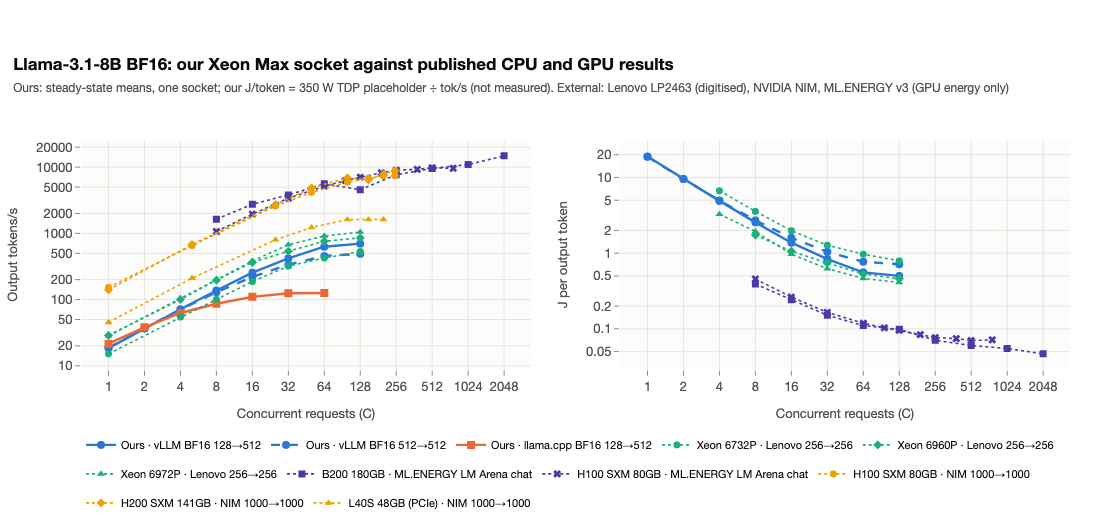

In [10]:
def series_from_ours(cid, wl, label, dash="solid"):
    g = points[(points["configuration_id"] == cid) & (points["workload"] == wl)]
    st = theme.configuration_style(cid)
    return pd.DataFrame({"label": label, "group": "ours", "origin": "ours", "color": st.color, "marker": st.symbol, "dash": dash,
                         "concurrency": g["concurrency"], "output_tok_s": g["output_tok_s_mean"], "energy": POWER_W / g["output_tok_s_mean"]})


SYMBOLS = ["circle", "diamond", "triangle-up", "square", "x"]
ext_rows = []
for (sid, hw, prec, ver, wl), g in refs[refs["precision"] == "bf16"].groupby(["source_id", "hardware", "precision", "engine_version", "workload"], sort=False):
    if sid not in ("lenovo_lp2463", "nvidia_nim", "mlenergy_v3"):
        continue
    short = hw.replace("NVIDIA ", "").replace("Intel ", "")
    ext_rows.append(pd.DataFrame({"label": f"{short} · {sid.split('_')[0].replace('nvidia', 'NIM').replace('lenovo', 'Lenovo').replace('mlenergy', 'ML.ENERGY')} {wl}",
                                  "group": sid, "origin": "external", "color": None, "marker": SYMBOLS[len(ext_rows) % len(SYMBOLS)], "dash": "dot",
                                  "concurrency": g["concurrency"], "output_tok_s": g["output_tok_s"], "energy": g["energy_j_per_output_token"]}))
series = pd.concat([series_from_ours("vllm_bf16", "decode", "Ours · vLLM BF16 128→512"),
                    series_from_ours("vllm_bf16", "balanced", "Ours · vLLM BF16 512→512", dash="dash"),
                    series_from_ours("llama_cpp_bf16", "decode", "Ours · llama.cpp BF16 128→512")] + ext_rows, ignore_index=True)
series.loc[series["label"].str.startswith("Ours · llama.cpp"), "energy"] = np.nan  # one estimated energy curve is enough
fig = plots.external_reference_figure(
    series, panels=[("output_tok_s", "Output tokens/s"), ("energy", "J per output token")],
    title="Llama-3.1-8B BF16: our Xeon Max socket against published CPU and GPU results",
    subtitle=f"Ours: steady-state means, one socket; our J/token = {num(POWER_W)} W TDP placeholder ÷ tok/s (not measured). "
             "External: Lenovo LP2463 (digitised), NVIDIA NIM, ML.ENERGY v3 (GPU energy only)")
fig.show()
export_figure(fig, "external_reference_bf16", source=NOTEBOOK,
              caption="Output tokens/s and J per output token against concurrency, Llama-3.1-8B BF16: our vLLM and llama.cpp curves (Xeon CPU Max 9480, one socket) "
                      "next to Lenovo's Xeon 6 vLLM runs, NVIDIA NIM on L40S/H100/H200 and ML.ENERGY on H100/B200; our energy is a 350 W TDP estimate.")

## 7. Checks and exports

In [11]:
gpu_cl = gpu[~gpu["scenario"].isin(external.PEAK_SCENARIOS)]
claims = [
    Claim("No external result matches one of our shapes exactly (no grade A row)", bool((comp["grade"] != "A").all()), f"{int((comp['grade'] == 'A').sum())} grade A rows"),
    Claim("Every GPU delivers more output tok/s than our vLLM at every paired closed-loop or batch-sweep point", bool((gpu_cl["adv_throughput"] > 1).all()), rng(gpu_cl["adv_throughput"], ratio)),
    Claim("Our socket sits between the 32-core and the 72/96-core Xeon 6 in BF16 throughput",
          bool((by["Intel Xeon 6732P"]["adv_throughput"] < 1).all() and (by["Intel Xeon 6972P"]["adv_throughput"] > 1).all() and (by["Intel Xeon 6960P"]["adv_throughput"] > 1).all()),
          f"6732P {rng(by['Intel Xeon 6732P']['adv_throughput'], ratio)}, 6960P {rng(by['Intel Xeon 6960P']['adv_throughput'], ratio)}, 6972P {rng(by['Intel Xeon 6972P']['adv_throughput'], ratio)}"),
    Claim("On the H100 and H200 at C = 50…200 our TTFT is within 1.5× of NIM's in either direction (BF16)", bool(((hi["adv_ttft"] <= 1.5) & (hi["adv_ttft"] >= 1 / 1.5)).all()), rng(hi["adv_ttft"], ratio)),
    Claim("Single-stream decode uses a similar share of the memory roof on our socket and on the GPUs (within 0.6–1.6×)",
          bool(0.6 <= o["roof_share"].median() / gb["roof_share"].median() <= 1.6), f"medians {pct(o['roof_share'].median(), 0, False)} vs {pct(gb['roof_share'].median(), 0, False)}"),
    Claim("Lenovo's implied power is within ±30% of our power placeholder (the energy comparison with Xeon 6 is not dominated by the boundary)",
          bool(((le_e["implied_power_w"] / POWER_W - 1).abs() <= 0.30).all()), rng(le_e["implied_power_w"])),
]
display(claims_table(claims))
export_table(comp, "external_reference_comparison")
export_table(bw, "external_decode_bandwidth")
export_table(pd.DataFrame(KEYS), "external_key_numbers")
display(table(pd.DataFrame(KEYS)[["key", "text", "description"]].rename(columns={"key": "Key", "text": "Value", "description": "Description"}), align="left",
              caption=f"External key numbers ({len(KEYS)}; exported to external_key_numbers.csv)"))

Holds,Statement,Evidence (computed)
✓,No external result matches one of our shapes exactly (no grade A row),0 grade A rows
✓,Every GPU delivers more output tok/s than our vLLM at every paired closed-loop or batch-sweep point,1.08×–21.1×
✓,Our socket sits between the 32-core and the 72/96-core Xeon 6 in BF16 throughput,"6732P 0.67×–0.82×, 6960P 1.21×–1.56×, 6972P 1.45×–1.60×"
✓,On the H100 and H200 at C = 50…200 our TTFT is within 1.5× of NIM's in either direction (BF16),0.79×–1.21×
✓,Single-stream decode uses a similar share of the memory roof on our socket and on the GPUs (within 0.6–1.6×),medians 59% vs 69%
✓,Lenovo's implied power is within ±30% of our power placeholder (the energy comparison with Xeon 6 is not dominated by the boundary),340–429


Key,Value,Description
ext_cpu_bf16_xeon6_96c_over_ours,1.45×–1.60×,"Xeon 6972P (96 cores, vLLM BF16, 256→256) output tok/s ÷ ours (vLLM BF16, 128→512), same C = 1…128 (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_72c_over_ours,1.21×–1.56×,"Xeon 6960P (72 cores) output tok/s ÷ ours, same C (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_32c_over_ours,0.67×–0.82×,"Xeon 6732P (32 cores) output tok/s ÷ ours, same C (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_ttft_ours_over_ext,0.07×–0.62×,"Our TTFT ÷ Lenovo's Xeon 6 TTFT, same C = 8…128 (< 1: ours lower; our prompts are shorter)"
ext_mlperf_cpu_offline_total_per_socket_over_ours,1.77×–2.81×,"MLPerf v5.1 CPU-only (2× Xeon 6980P W4A8; 2× Xeon 6787P W8A8) Offline total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128"
ext_mlperf_cpu_server_total_per_socket_over_ours,0.63×–1.03×,"MLPerf v5.1 CPU-only Server total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128"
ext_gpu_bf16_h100_over_ours,7.67×–15.1×,"NIM H100 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C (C = 1…250)"
ext_gpu_bf16_h200_over_ours,7.50×–17.9×,"NIM H200 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C"
ext_gpu_bf16_l40s_over_ours,2.37×–3.30×,"NIM L40S BF16 1000→1000 output tok/s ÷ our vLLM BF16 512→512, nearest C"
ext_gpu_bf16_tpot_c1_over_ours,2.40×–8.10×,"Our C=1 median TPOT ÷ NIM mean ITL (L40S, H100, H200; BF16)"


## Conclusions

- **Other CPUs (measured by others, compared by us).** In BF16 with vLLM, our 55-core Xeon Max socket is in the same range as
  current Xeon 6 servers. It is behind the 72- and 96-core parts and ahead of the 32-core part (section 2.1). Our TTFT is
  lower than theirs at equal concurrency, partly because our prompts are shorter. We are **not far off** the CPU state of
  the art; the remaining gap is of the order of core count and memory generation.
- **GPUs.** A single data-center GPU delivers several times to an order of magnitude more output tokens/s than our socket.
  The gap is smallest for the L40S and in single-stream decode, where it tracks the memory-bandwidth ratio. It is largest at
  high concurrency, where the GPUs keep scaling and our socket plateaus near C = 128. The GPUs use their bandwidth about as
  efficiently as we use ours (section 5), so the C = 1 gap is mostly hardware.
- **Where a CPU is closest.** TTFT at high load is comparable. Energy per token is several times worse than a GPU and close
  to a Xeon 6 server, but our side of that comparison is an estimate until the socket's power is measured.
- **Next steps.**
  1. Measure energy (Slurm `ConsumedEnergy` per job, or RAPL if access is granted) and set `POWER_W`.
  2. Run one external shape on our side (1000→1000 for NIM; 256→256 for Lenovo) to turn the best grade-B pairs into grade A.

## Limitations

- **No exact match, and different statistics.** No external row matches our shape, so every ratio mixes the hardware gap with
  a workload difference. The statistics also differ: NIM reports mean TTFT and ITL, ours are medians, and Lenovo's metric
  definitions are not stated.
- **Digitised values.** Lenovo's values are digitised from its figures (about ±2%). Its text quotes efficiencies 10–20% lower
  than its Figure 2 shows, and its socket count and power boundary are not stated.
- **Mismatched energy boundaries.** ML.ENERGY counts GPU energy only. Ours is a TDP placeholder.
- **MLPerf comparison.** The MLPerf rows use other quantisation (W4A8, FP8) and a dataset with no counterpart among our shapes.
  They are compared on total tokens/s for context only.
- **Vendor sources.** Vendor documents report best-case configurations of their own products.